# TF-IDF Baseline
This notebook implements a basic TF-IDF cosine similarity baseline for short-answer grading.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys

# Ensure we can import from src
sys.path.insert(0, '../')

from src.baselines import calculate_tfidf_cosine
from src.metrics import evaluate, append_results
from sklearn.linear_model import LinearRegression

os.makedirs('../results/figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)


## 1. Load Data
We load the `dev.csv` and `test.csv` subsets.

In [2]:
df_dev = pd.read_csv('../data/processed/dev.csv')
df_test = pd.read_csv('../data/processed/test.csv')


## 2. Fit TF-IDF and Calculate Cosine Similarity
To avoid data leakage, we fit the `TfidfVectorizer` **only** on the DEV set (both reference and student answers). We then transform both DEV and TEST sets.

In [3]:
# Fit corpus consists of all dev reference answers and dev student answers
fit_corpus = list(df_dev['reference_answer'].unique()) + list(df_dev['student_answer'])

dev_cosines = calculate_tfidf_cosine(df_dev['reference_answer'], df_dev['student_answer'], fit_corpus)
test_cosines = calculate_tfidf_cosine(df_test['reference_answer'], df_test['student_answer'], fit_corpus)


## 3. Two Prediction Methods
(a) **Simple Linear Scaling**: `score = 5 * cosine`

(b) **Linear Regression (Calibrated)**: Train a linear model on the DEV set, then apply to the TEST set (clipped to `[0, 5]`).

In [4]:
# (a) Simple Linear Scaling
pred_scaled_test = dev_scaled_test = 5.0 * test_cosines
pred_scaled_test = np.clip(pred_scaled_test, 0, 5)

# (b) Linear Regression Calibrated
lr = LinearRegression()
lr.fit(dev_cosines.reshape(-1, 1), df_dev['human_score'])

pred_calibrated_test = lr.predict(test_cosines.reshape(-1, 1))
pred_calibrated_test = np.clip(pred_calibrated_test, 0, 5)

# Attach to df_test for export
df_test['pred_scaled'] = pred_scaled_test
df_test['pred_calibrated'] = pred_calibrated_test

# Save predictions
df_test[['row_id', 'question_id', 'human_score', 'student_answer', 'pred_scaled', 'pred_calibrated']].to_csv('../results/preds_tfidf.csv', index=False)
print("Predictions saved to results/preds_tfidf.csv")


Predictions saved to results/preds_tfidf.csv


## 4. Evaluation & Append to Results
Evaluate on the TEST set using `src.metrics.evaluate`.

In [5]:
metrics_scaled = evaluate(df_test['human_score'], pred_scaled_test)
metrics_calib = evaluate(df_test['human_score'], pred_calibrated_test)

print("TF-IDF Scaled Metrics:", metrics_scaled)
print("TF-IDF Calibrated Metrics:", metrics_calib)

append_results('TF-IDF (Scaled)', metrics_scaled, '../results/main_results.csv')
append_results('TF-IDF (Calibrated)', metrics_calib, '../results/main_results.csv')
print("Appended to results/main_results.csv")


TF-IDF Scaled Metrics: {'mae': 2.3674433620519397, 'rmse': np.float64(2.7290752257132773), 'pearson': np.float64(0.16766933025261932), 'spearman': np.float64(0.2290636052588917), 'qwk': 0.08462960948547804, 'within_1': np.float64(0.20666666666666667)}
TF-IDF Calibrated Metrics: {'mae': 0.8700854419927142, 'rmse': np.float64(1.1797849750121654), 'pearson': np.float64(0.1783474710458994), 'spearman': np.float64(0.2308377854159452), 'qwk': 0.1634910307649411, 'within_1': np.float64(0.6266666666666667)}
Appended to results/main_results.csv


## 5. Visualizations
Scatter plot of human vs predicted scores, and an error histogram.

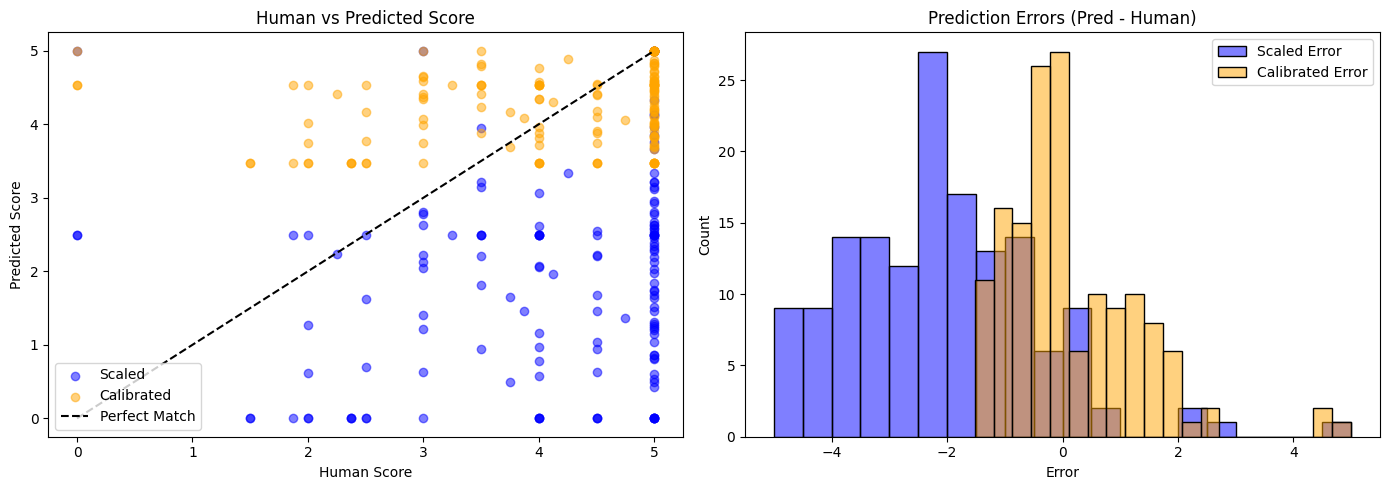

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
axes[0].scatter(df_test['human_score'], pred_scaled_test, alpha=0.5, label='Scaled', color='blue')
axes[0].scatter(df_test['human_score'], pred_calibrated_test, alpha=0.5, label='Calibrated', color='orange')
axes[0].plot([0, 5], [0, 5], 'k--', label='Perfect Match')
axes[0].set_title('Human vs Predicted Score')
axes[0].set_xlabel('Human Score')
axes[0].set_ylabel('Predicted Score')
axes[0].legend()

# Error Histogram
errors_scaled = pred_scaled_test - df_test['human_score']
errors_calib = pred_calibrated_test - df_test['human_score']

sns.histplot(errors_scaled, bins=20, alpha=0.5, label='Scaled Error', color='blue', ax=axes[1])
sns.histplot(errors_calib, bins=20, alpha=0.5, label='Calibrated Error', color='orange', ax=axes[1])
axes[1].set_title('Prediction Errors (Pred - Human)')
axes[1].set_xlabel('Error')
axes[1].legend()

plt.tight_layout()
plt.savefig('../results/figures/tfidf_scatter_error.png', dpi=300)
plt.show()
